# Data Centers and Virginia's Power Bills (Annually)

Conner Aylward and Carlos Shimabukuro

Data: U.S. Energy Information Administration (EIA), sales to ultimate customers by state and sector (EIA-861)

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

def clean_annual():
    states = ["VA", "MD", "NC", "US"]
    cols = [0, 1, 3, 5, 7, 11]
    names = ["year", "state", "res_sales", "res_price", "com_sales", "ind_sales"]

    old = pd.read_excel("data/raw/HS861 1990-2009.xlsx", sheet_name="Total Electric Industry", skiprows=3, header=None)
    new = pd.read_excel("data/raw/HS861 2010-.xlsx", sheet_name="Total Electric Industry", skiprows=3, header=None)

    # EIA folded "Other" into Commercial in 2003, so add it back in for 1990-2002
    old[7] = old[7] + pd.to_numeric(old[19], errors="coerce").fillna(0)

    df = pd.concat([old[cols], new[cols]])
    df.columns = names
    df = df[df["state"].isin(states)]
    df["year"] = df["year"].astype(int)
    df = df.sort_values(["state", "year"]).reset_index(drop=True)

    df.to_csv("data/clean/annual_sales.csv", index=False)
    return df

annual = clean_annual()
annual[annual["state"] == "VA"].tail()

,year,state,res_sales,res_price,com_sales,ind_sales
139,2021,VA,46634411.0,11.96,58723978.0,19712199.0
140,2022,VA,46717547.0,13.34,68556082.0,16861186.0
141,2023,VA,43095838.0,14.26,73807035.0,15176022.0
142,2024,VA,45272825.0,14.41,78710662.0,13775530.0
143,2025,VA,47172714.0,15.28,86624448.0,13497696.0


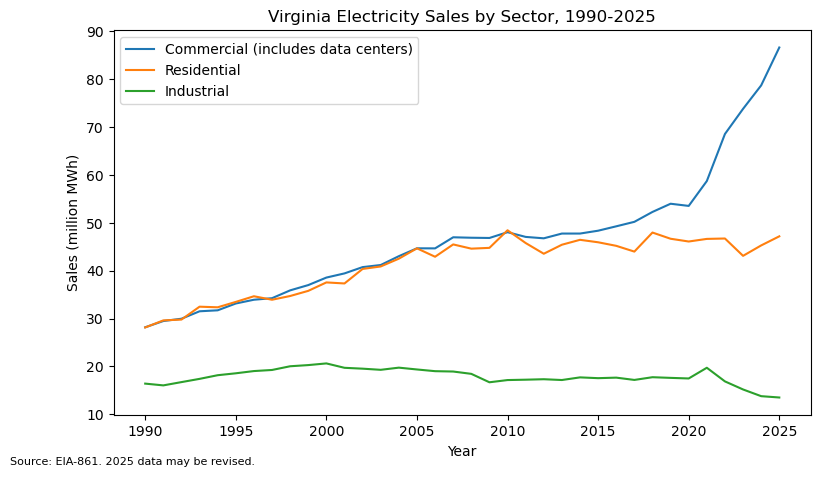

In [6]:
def plot_annual(df):
    va = df[df["state"] == "VA"]

    plt.figure(figsize=(9, 5))
    plt.plot(va["year"], va["com_sales"] / 1e6, label="Commercial (includes data centers)")
    plt.plot(va["year"], va["res_sales"] / 1e6, label="Residential")
    plt.plot(va["year"], va["ind_sales"] / 1e6, label="Industrial")

    plt.title("Virginia Electricity Sales by Sector, 1990-2025")
    plt.xlabel("Year")
    plt.ylabel("Sales (million MWh)")
    plt.legend()
    plt.figtext(0.01, 0.01, "Source: EIA-861. 2025 data may be revised.", fontsize=8)

    plt.savefig("figures/fig1_va_sales_by_sector.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_annual(annual)

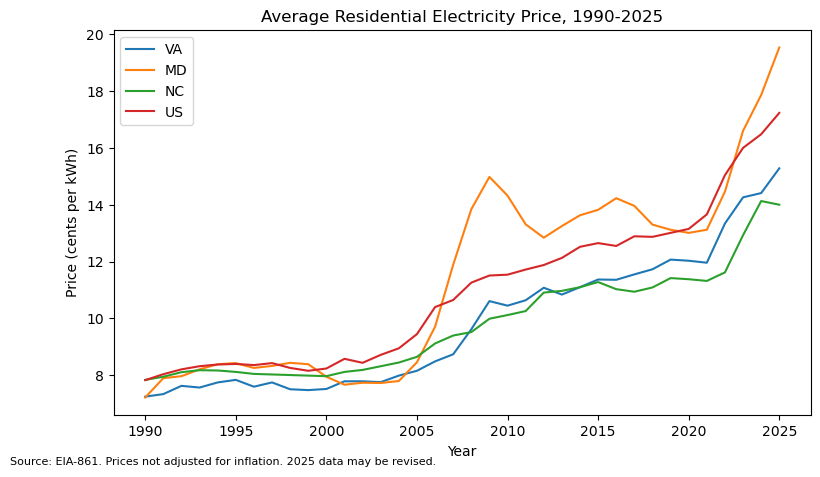

In [7]:
def plot_prices(df):
    plt.figure(figsize=(9, 5))

    for state in ["VA", "MD", "NC", "US"]:
        s = df[df["state"] == state]
        plt.plot(s["year"], s["res_price"], label=state)

    plt.title("Average Residential Electricity Price, 1990-2025")
    plt.xlabel("Year")
    plt.ylabel("Price (cents per kWh)")
    plt.legend()
    plt.figtext(0.01, 0.01, "Source: EIA-861. Prices not adjusted for inflation. 2025 data may be revised.", fontsize=8)

    plt.savefig("figures/fig2_residential_prices.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_prices(annual)